## 🔧 Importazione librerie

In [7]:
# ============================================================
# IMPORT DELLE LIBRERIE
# ============================================================
#
# Le librerie sono già indicate nel requirements.txt.
# Qui ci limitiamo a importarle.
# ============================================================

import re
import math
import collections

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import spacy

from nltk.corpus import stopwords
from collections import Counter, defaultdict
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

from gensim.models import Word2Vec
from gensim.models import FastText

from wordcloud import WordCloud


# ============================================================
# RISORSE NLTK
# ============================================================
#
# NLTK è installato tramite requirements.txt.
# Alcune risorse linguistiche, invece, devono essere scaricate.
# ============================================================

nltk.download("punkt")
nltk.download("stopwords")


# ============================================================
# CONTROLLO DELL'AMBIENTE PYTHON
# ============================================================
#
# Questo comando ci dice quale Python sta realmente eseguendo
# il notebook.
#
# È molto utile quando:
# - una libreria sembra installata;
# - ma il notebook continua a non trovarla.
# ============================================================

import sys

print("Python utilizzato dal notebook:")
print(sys.executable)

Python utilizzato dal notebook:
c:\Users\A1627apulia\Desktop\Generative-AI\lezione_3-11-09-2026\tf_env\Scripts\python.exe


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\A1627apulia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\A1627apulia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 🎒 Bag of Words (BoW)

🎒 BAG OF WORDS

📝 DOCUMENTI DI ESEMPIO:
   1. il gatto dorme sul divano
   2. il cane corre nel parco
   3. il gatto e il cane sono amici
   4. sul divano c'è un gatto nero
   5. nel parco corrono molti cani

📚 VOCABOLARIO (18 parole):
['amici', "c'è", 'cane', 'cani', 'corre', 'corrono', 'divano', 'dorme', 'e', 'gatto', 'il', 'molti', 'nel', 'nero', 'parco', 'sono', 'sul', 'un']

🔢 MATRICE BAG OF WORDS (5 documenti x 18 parole):


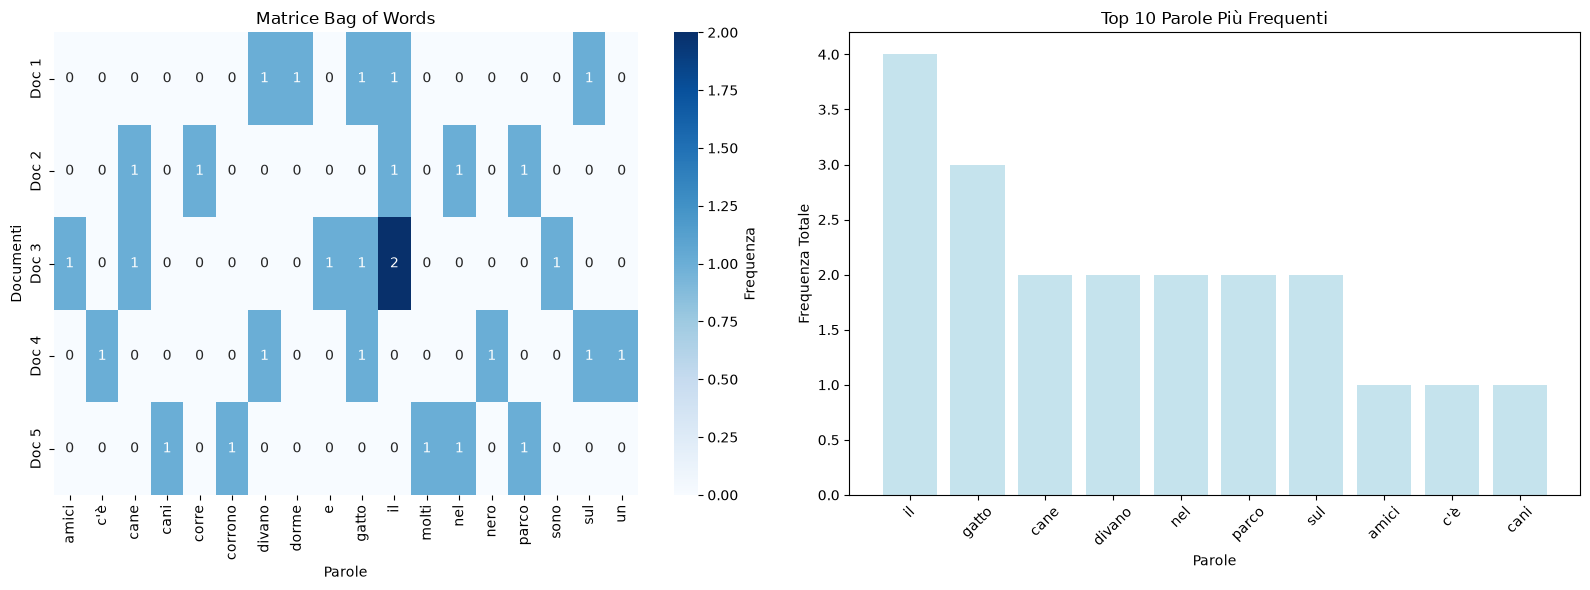


📊 Matrice di similarità tra documenti:


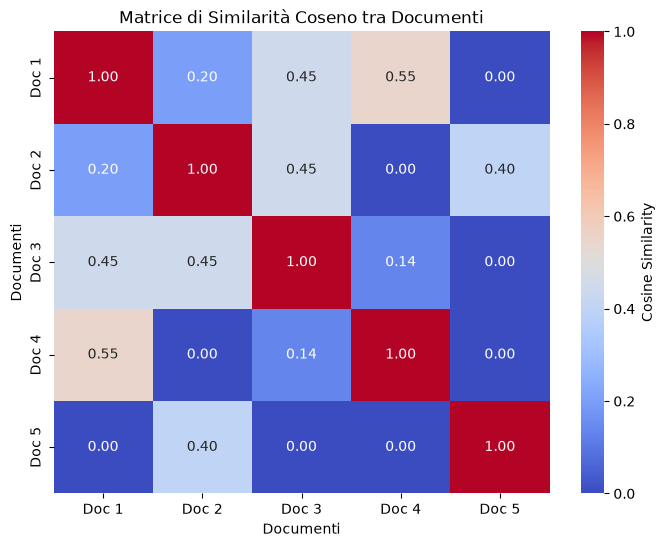

In [8]:
# ============================================================
# BAG OF WORDS
# ============================================================

class BagOfWords:
    def __init__(self):
        # Dati che descrivono il vocabolario
        self.vocabolario = {}
        self.vocabolario_inverso = {}
        self.dimensione_vocab = 0
    
    def costruisci_vocabolario(self, documenti):
        """Costruisce il vocabolario da una lista di documenti"""
        
        # Set = insieme di parole senza duplicati
        tutte_parole = set()

        for doc in documenti:
            parole = doc.lower().split()
            tutte_parole.update(parole)
        
        # Assegniamo a ogni parola un indice numerico
        for i, parola in enumerate(sorted(tutte_parole)):
            self.vocabolario[parola] = i
            self.vocabolario_inverso[i] = parola
        
        self.dimensione_vocab = len(self.vocabolario)
    
    def documento_to_vettore(self, documento):
        """Converte un documento in vettore BoW"""
        
        # Il vettore ha una posizione per ogni parola del vocabolario
        vettore = np.zeros(self.dimensione_vocab)
        parole = documento.lower().split()

        # Ogni parola aumenta di 1 la propria posizione nel vettore
        for parola in parole:
            if parola in self.vocabolario:
                indice = self.vocabolario[parola]
                vettore[indice] += 1
        
        return vettore
    
    def trasforma_documenti(self, documenti):
        """Trasforma una lista di documenti in matrice BoW"""
        
        matrice = []
        
        for doc in documenti:
            vettore = self.documento_to_vettore(doc)
            matrice.append(vettore)
        
        # Ogni riga = un documento
        # Ogni colonna = una parola del vocabolario
        return np.array(matrice)


# ============================================================
# DOCUMENTI DI ESEMPIO
# ============================================================

print("🎒 BAG OF WORDS\n")

documenti_esempio = [
    "il gatto dorme sul divano",
    "il cane corre nel parco",
    "il gatto e il cane sono amici",
    "sul divano c'è un gatto nero",
    "nel parco corrono molti cani"
]

print("📝 DOCUMENTI DI ESEMPIO:")
for i, doc in enumerate(documenti_esempio, 1):
    print(f"   {i}. {doc}")


# ============================================================
# COSTRUZIONE DEL VOCABOLARIO
# ============================================================

bow = BagOfWords()
bow.costruisci_vocabolario(documenti_esempio)

print(f"\n📚 VOCABOLARIO ({bow.dimensione_vocab} parole):")
print(list(bow.vocabolario.keys()))


# ============================================================
# TRASFORMAZIONE IN MATRICE BAG OF WORDS
# ============================================================

matrice_bow = bow.trasforma_documenti(documenti_esempio)

print(
    f"\n🔢 MATRICE BAG OF WORDS "
    f"({matrice_bow.shape[0]} documenti x {matrice_bow.shape[1]} parole):"
)


# DataFrame per visualizzare meglio la matrice
df_bow = pd.DataFrame(
    matrice_bow,
    columns=list(bow.vocabolario.keys()),
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

#print(df_bow)


# ============================================================
# VISUALIZZAZIONE DELLA MATRICE
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap: mostra quante volte ogni parola compare in ogni documento
sns.heatmap(
    df_bow,
    annot=True,
    cmap='Blues',
    ax=ax1,
    cbar_kws={'label': 'Frequenza'}
)

ax1.set_title('Matrice Bag of Words')
ax1.set_xlabel('Parole')
ax1.set_ylabel('Documenti')


# Frequenze totali delle parole
freq_parole = matrice_bow.sum(axis=0)

parole_ordinate = sorted(
    bow.vocabolario.keys(),
    key=lambda x: freq_parole[bow.vocabolario[x]],
    reverse=True
)

freq_ordinate = [
    freq_parole[bow.vocabolario[p]]
    for p in parole_ordinate[:10]
]

ax2.bar(
    parole_ordinate[:10],
    freq_ordinate,
    color='lightblue',
    alpha=0.7
)

ax2.set_title('Top 10 Parole Più Frequenti')
ax2.set_xlabel('Parole')
ax2.set_ylabel('Frequenza Totale')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# SIMILARITÀ COSENO
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

similarita = cosine_similarity(matrice_bow)

# Trasformiamo il risultato in DataFrame per leggerlo meglio
df_similarita = pd.DataFrame(
    similarita,
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))],
    columns=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

print("\n📊 Matrice di similarità tra documenti:")
#print(df_similarita)


# ============================================================
# HEATMAP DELLA SIMILARITÀ
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    df_similarita,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    cbar_kws={'label': 'Cosine Similarity'}
)

plt.title('Matrice di Similarità Coseno tra Documenti')
plt.xlabel('Documenti')
plt.ylabel('Documenti')
plt.show()

## 📊 Term Frequency - Inverse Document Frequency (TF-IDF)

📊 TF-IDF

📚 Vocabolario TF-IDF: 18 parole

🔢 PUNTEGGI IDF (Inverse Document Frequency):
   'dorme': 1.609
   'corre': 1.609
   'amici': 1.609
   'e': 1.609
   'sono': 1.609
   'c'è': 1.609
   'un': 1.609
   'nero': 1.609
   'corrono': 1.609
   'molti': 1.609
   'cani': 1.609
   'divano': 0.916
   'sul': 0.916
   'cane': 0.916
   'parco': 0.916
   'nel': 0.916
   'gatto': 0.511
   'il': 0.511


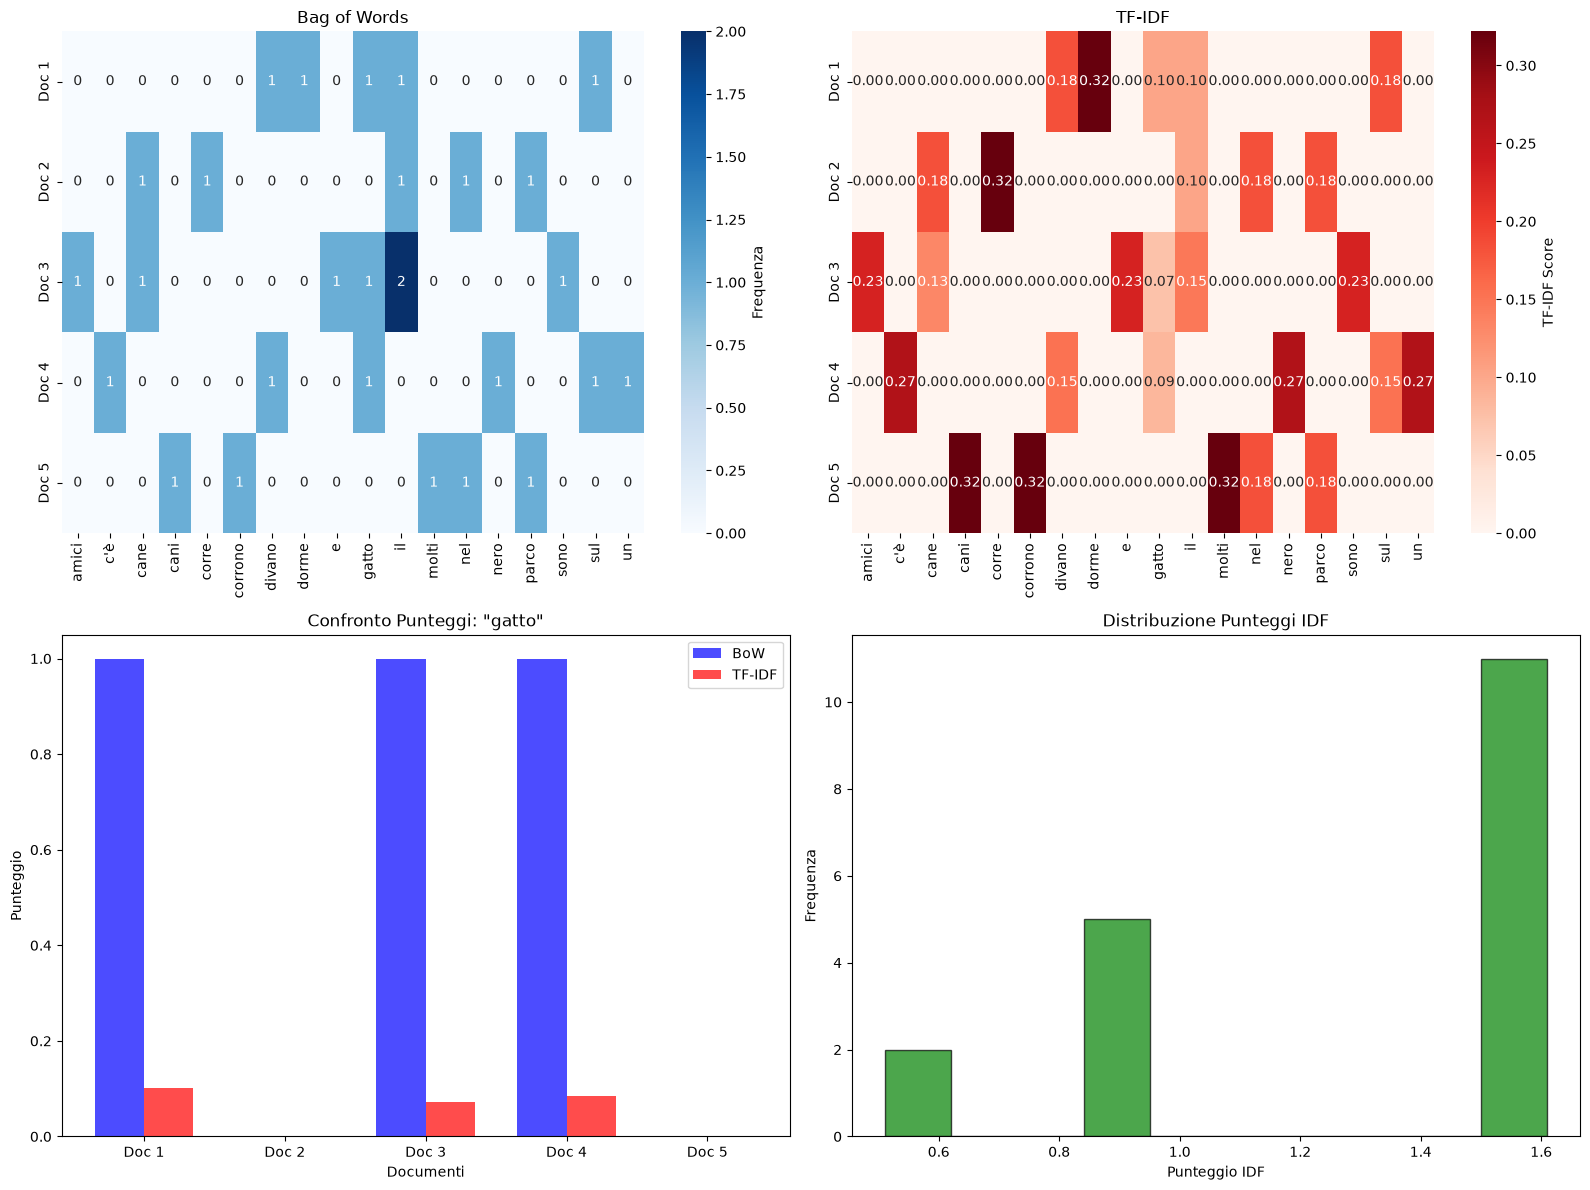

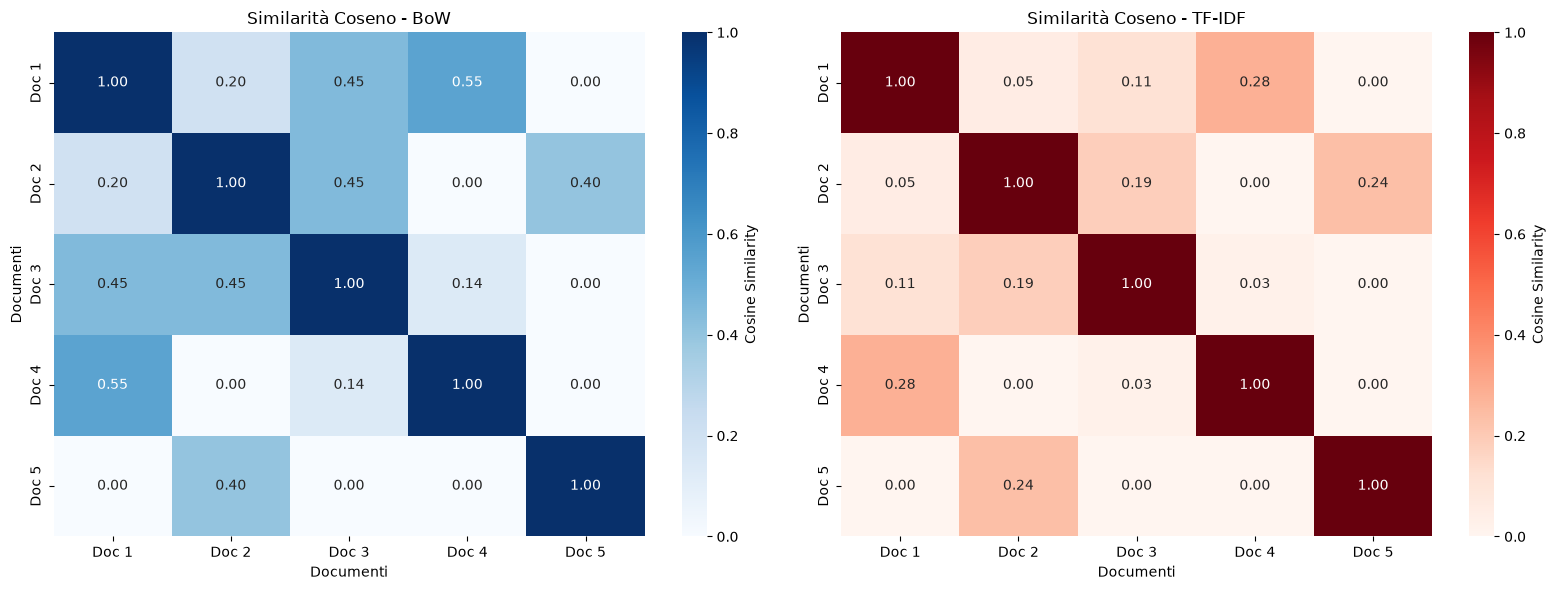

In [9]:
# ============================================================
# TF-IDF
# ============================================================

class TFIDF:
    def __init__(self):
        # Dati che il modello deve conservare
        self.vocabolario = {}
        self.idf_scores = {}
        self.dimensione_vocab = 0
    
    def calcola_tf(self, documento):
        """Calcola Term Frequency per un documento"""
        
        parole = documento.lower().split()
        tf = Counter(parole)
        
        # TF = frequenza della parola / numero totale di parole
        lunghezza_doc = len(parole)
        
        for parola in tf:
            tf[parola] = tf[parola] / lunghezza_doc
        
        return tf
    
    def calcola_idf(self, documenti):
        """Calcola Inverse Document Frequency"""
        
        n_documenti = len(documenti)
        
        # Contiamo in quanti documenti compare ogni parola
        df = defaultdict(int)

        for doc in documenti:
            # Usiamo un set: una parola conta una sola volta per documento
            parole_uniche = set(doc.lower().split())
            
            for parola in parole_uniche:
                df[parola] += 1
        
        # IDF: più una parola è rara, maggiore sarà il suo peso
        for parola, freq_doc in df.items():
            self.idf_scores[parola] = math.log(n_documenti / freq_doc)
        
        # Assegniamo un indice numerico a ogni parola
        for i, parola in enumerate(sorted(df.keys())):
            self.vocabolario[parola] = i
        
        self.dimensione_vocab = len(self.vocabolario)
    
    def documento_to_tfidf(self, documento):
        """Converte documento in vettore TF-IDF"""
        
        tf = self.calcola_tf(documento)
        
        # Creiamo un vettore con una posizione per ogni parola
        vettore = np.zeros(self.dimensione_vocab)
        
        for parola, tf_score in tf.items():
            if parola in self.vocabolario:
                indice = self.vocabolario[parola]
                idf_score = self.idf_scores[parola]
                
                # Il peso TF-IDF nasce da TF × IDF
                vettore[indice] = tf_score * idf_score
        
        return vettore
    
    def fit_transform(self, documenti):
        """Calcola IDF e trasforma i documenti in vettori TF-IDF"""
        
        self.calcola_idf(documenti)

        # Ogni documento viene trasformato in un vettore
        matrice = []
        
        for doc in documenti:
            vettore = self.documento_to_tfidf(doc)
            matrice.append(vettore)
        
        # Ogni riga = un documento
        # Ogni colonna = una parola del vocabolario
        return np.array(matrice)


# ============================================================
# TEST TF-IDF
# ============================================================

print("📊 TF-IDF\n")

tfidf = TFIDF()
matrice_tfidf = tfidf.fit_transform(documenti_esempio)

print(f"📚 Vocabolario TF-IDF: {tfidf.dimensione_vocab} parole")


# ============================================================
# PUNTEGGI IDF
# ============================================================

print("\n🔢 PUNTEGGI IDF (Inverse Document Frequency):")

idf_ordinati = sorted(
    tfidf.idf_scores.items(),
    key=lambda x: x[1],
    reverse=True
)

for parola, idf in idf_ordinati:
    print(f"   '{parola}': {idf:.3f}")


# ============================================================
# CONFRONTO BoW vs TF-IDF
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# DataFrame per visualizzare la matrice TF-IDF
df_tfidf = pd.DataFrame(
    matrice_tfidf,
    columns=list(tfidf.vocabolario.keys()),
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)


# Matrice BoW
sns.heatmap(
    df_bow,
    annot=True,
    cmap='Blues',
    ax=axes[0,0],
    cbar_kws={'label': 'Frequenza'}
)

axes[0,0].set_title('Bag of Words')


# Matrice TF-IDF
sns.heatmap(
    df_tfidf,
    annot=True,
    fmt='.2f',
    cmap='Reds',
    ax=axes[0,1],
    cbar_kws={'label': 'TF-IDF Score'}
)

axes[0,1].set_title('TF-IDF')


# ============================================================
# CONFRONTO DI UNA PAROLA
# ============================================================

parola_esempio = 'gatto'

if parola_esempio in bow.vocabolario and parola_esempio in tfidf.vocabolario:
    
    idx_bow = bow.vocabolario[parola_esempio]
    idx_tfidf = tfidf.vocabolario[parola_esempio]
    
    bow_scores = matrice_bow[:, idx_bow]
    tfidf_scores = matrice_tfidf[:, idx_tfidf]
    
    x = np.arange(len(documenti_esempio))
    width = 0.35
    
    axes[1,0].bar(
        x - width/2,
        bow_scores,
        width,
        label='BoW',
        alpha=0.7,
        color='blue'
    )
    
    axes[1,0].bar(
        x + width/2,
        tfidf_scores,
        width,
        label='TF-IDF',
        alpha=0.7,
        color='red'
    )
    
    axes[1,0].set_title(f'Confronto Punteggi: "{parola_esempio}"')
    axes[1,0].set_xlabel('Documenti')
    axes[1,0].set_ylabel('Punteggio')
    axes[1,0].set_xticks(x)
    axes[1,0].set_xticklabels(
        [f'Doc {i+1}' for i in range(len(documenti_esempio))]
    )
    axes[1,0].legend()


# Distribuzione dei valori IDF
idf_values = list(tfidf.idf_scores.values())

axes[1,1].hist(
    idf_values,
    bins=10,
    alpha=0.7,
    color='green',
    edgecolor='black'
)

axes[1,1].set_title('Distribuzione Punteggi IDF')
axes[1,1].set_xlabel('Punteggio IDF')
axes[1,1].set_ylabel('Frequenza')

plt.tight_layout()
plt.show()


# ============================================================
# SIMILARITÀ COSENO
# ============================================================

sim_bow = cosine_similarity(matrice_bow)
sim_tfidf = cosine_similarity(matrice_tfidf)

# Trasformiamo le matrici in DataFrame per leggerle meglio
df_sim_bow = pd.DataFrame(
    sim_bow,
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))],
    columns=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

df_sim_tfidf = pd.DataFrame(
    sim_tfidf,
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))],
    columns=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)


# ============================================================
# CONFRONTO SIMILARITÀ BoW vs TF-IDF
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


sns.heatmap(
    df_sim_bow,
    annot=True,
    fmt=".2f",
    cmap='Blues',
    ax=axes[0],
    cbar_kws={'label': 'Cosine Similarity'}
)

axes[0].set_title('Similarità Coseno - BoW')
axes[0].set_xlabel('Documenti')
axes[0].set_ylabel('Documenti')


sns.heatmap(
    df_sim_tfidf,
    annot=True,
    fmt=".2f",
    cmap='Reds',
    ax=axes[1],
    cbar_kws={'label': 'Cosine Similarity'}
)

axes[1].set_title('Similarità Coseno - TF-IDF')
axes[1].set_xlabel('Documenti')
axes[1].set_ylabel('Documenti')

plt.tight_layout()
plt.show()

## 📊 N-grams

🌿 Testo originale

Machine learning e deep learning sono parti dell'intelligenza artificiale. 
Il machine learning migliora grazie al deep learning. 
Molti parlano di machine learning ogni giorno.


🎯 Tokens dopo la pre-elaborazione
['machine', 'learning', 'deep', 'learning', 'essere', 'parte', 'intelligenza', 'artificiale', 'machine', 'learning', 'migliorare', 'grazie', 'deep', 'learning', 'molto', 'parlare', 'machine', 'learning', 'ogni', 'giorno']

1️⃣ Unigrams
`['machine', 'learning', 'deep', 'learning', 'essere', 'parte', 'intelligenza', 'artificiale', 'machine', 'learning', 'migliorare', 'grazie', 'deep', 'learning', 'molto', 'parlare', 'machine', 'learning', 'ogni', 'giorno']`

2️⃣ Bigrams
`['machine learning', 'learning deep', 'deep learning', 'learning essere', 'essere parte', 'parte intelligenza', 'intelligenza artificiale', 'artificiale machine', 'machine learning', 'learning migliorare', 'migliorare grazie', 'grazie deep', 'deep learning', 'learning molto', 'molto parlare',

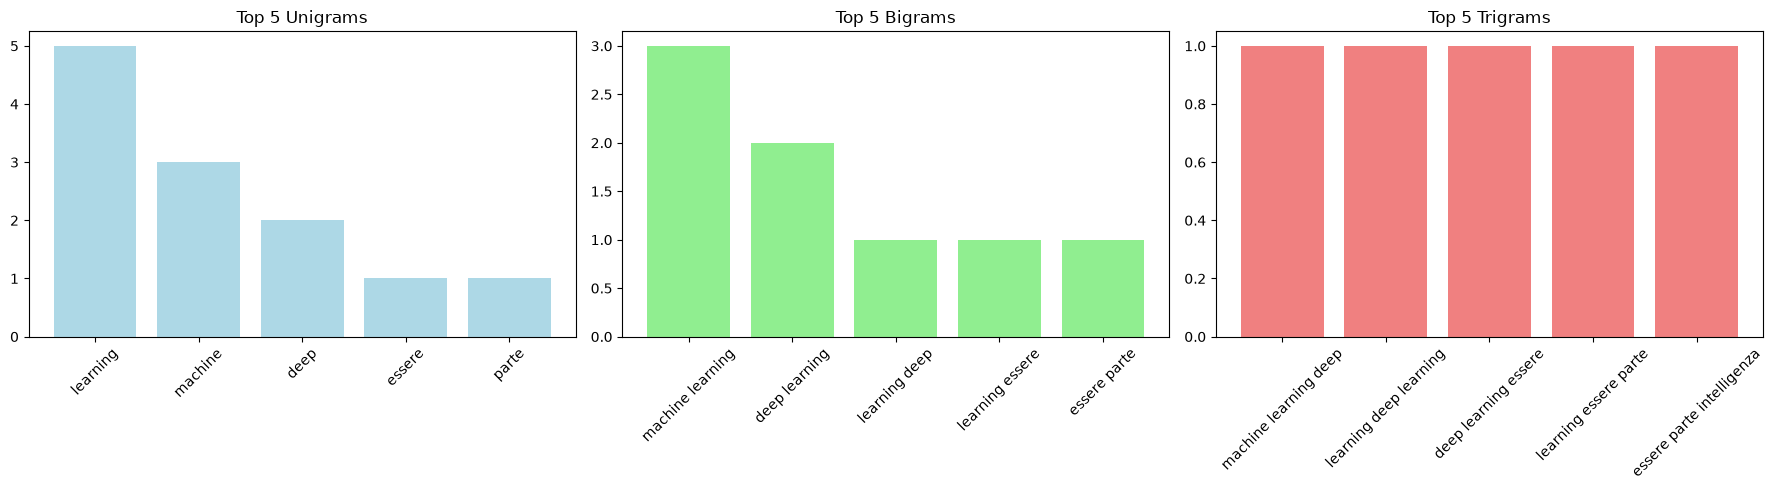

In [11]:
# ============================================================
# N-GRAM E STEMMING
# ============================================================

from nltk.util import ngrams
from nltk.stem import SnowballStemmer


# ============================================================
# PIPELINE DI PRE-ELABORAZIONE
# ============================================================

class PipelinePreelaborazione:
    
    def __init__(self, lingua='italian'):
        """Inizializza la pipeline"""
        
        self.lingua = lingua
        
        # Carica il modello linguistico SpaCy
        self.nlp = spacy.load(
            'it_core_news_sm' if lingua == 'italian' else 'en_core_web_sm'
        )
        
        self.stemmer = SnowballStemmer(lingua)
        self.stop_words = set(stopwords.words(lingua))
        
        # Conserviamo alcune statistiche del processo
        self.stats = {
            'testi_processati': 0,
            'token_originali': 0,
            'token_finali': 0,
            'stop_words_rimosse': 0
        }
    
    def pulisci_testo(self, testo):
        """Pulizia base del testo"""
        
        # Portiamo il testo in una forma più uniforme
        testo = testo.lower()
        
        # Rimuoviamo elementi che normalmente non servono all'analisi linguistica
        testo = re.sub(r'http\S+|www\S+|https\S+', '', testo)
        testo = re.sub(r'\S+@\S+', '', testo)
        testo = re.sub(r'#\w+|@\w+', '', testo)
        testo = re.sub(r'\d+', '', testo)
        testo = re.sub(r'[^\w\s]', ' ', testo)
        testo = re.sub(r'\s+', ' ', testo).strip()
        
        return testo
    
    def tokenizza_e_lemmatizza(self, testo):
        """Tokenizzazione e lemmatizzazione"""
        
        # SpaCy analizza il testo e lo divide in token
        doc = self.nlp(testo)
        tokens = []
        
        for token in doc:
            
            # Ignoriamo punteggiatura, spazi e token troppo corti
            if not token.is_punct and not token.is_space and len(token.text) > 2:
                
                # Riduciamo la parola alla sua forma base (lemma)
                if token.lemma_ != '-PRON-':
                    tokens.append(token.lemma_)
                else:
                    tokens.append(self.stemmer.stem(token.text))
        
        return tokens
    
    def rimuovi_stop_words(self, tokens):
        """Rimuove stop words"""
        
        tokens_filtrati = []
        stop_words_rimosse = 0
        
        for token in tokens:
            if token not in self.stop_words:
                tokens_filtrati.append(token)
            else:
                stop_words_rimosse += 1
        
        self.stats['stop_words_rimosse'] += stop_words_rimosse
        
        return tokens_filtrati
    
    def processa_testo(self, testo, rimuovi_stop=True, min_lunghezza=2):
        """Esegue tutti gli step della pipeline"""
        
        # 1. Pulizia del testo
        testo_pulito = self.pulisci_testo(testo)
        
        # 2. Tokenizzazione + lemmatizzazione
        tokens = self.tokenizza_e_lemmatizza(testo_pulito)
        
        self.stats['token_originali'] += len(tokens)
        
        # 3. Rimozione delle stop words
        if rimuovi_stop:
            tokens = self.rimuovi_stop_words(tokens)
        
        # 4. Eliminiamo i token troppo corti
        tokens = [
            token for token in tokens
            if len(token) >= min_lunghezza
        ]
        
        self.stats['token_finali'] += len(tokens)
        self.stats['testi_processati'] += 1
        
        return tokens


# ============================================================
# GENERAZIONE DEGLI N-GRAM
# ============================================================

def mostra_ngrams(testo):
    
    # 'testo' contiene già i token prodotti dalla pipeline
    tokens = testo
    
    # Creiamo sequenze di 1, 2 e 3 parole consecutive
    unigrams = list(ngrams(tokens, 1))
    bigrams = list(ngrams(tokens, 2))
    trigrams = list(ngrams(tokens, 3))
    
    
    # --------------------------------------------------------
    # VISUALIZZAZIONE DEI TOKEN
    # --------------------------------------------------------
    
    print("\n🎯 Tokens dopo la pre-elaborazione")
    print(tokens)
    
    print("\n1️⃣ Unigrams")
    print(f"`{[' '.join(t) for t in unigrams]}`")
    
    print("\n2️⃣ Bigrams")
    print(f"`{[' '.join(t) for t in bigrams]}`")
    
    print("\n3️⃣ Trigrams")
    print(f"`{[' '.join(t) for t in trigrams]}`")
    
    
    # --------------------------------------------------------
    # FREQUENZA DEI BIGRAM
    # --------------------------------------------------------
    
    # Counter conta quante volte compare ogni n-gram
    bigram_freq = Counter(bigrams)
    
    print("\n📊 Frequenze Bigram")
    
    for k, v in bigram_freq.items():
        print(f"`{' '.join(k)}` : {v}")
    
    
    # Frequenze di unigram, bigram e trigram
    uni_freq = Counter(unigrams)
    bi_freq = Counter(bigrams)
    tri_freq = Counter(trigrams)
    
    
    # Selezioniamo i 5 n-gram più frequenti
    top_n = 5
    
    uni_top = uni_freq.most_common(top_n)
    bi_top = bi_freq.most_common(top_n)
    tri_top = tri_freq.most_common(top_n)
    
    
    # Prepariamo i dati per i grafici
    labels_uni = [' '.join(t[0]) for t in uni_top]
    values_uni = [t[1] for t in uni_top]
    
    labels_bi = [' '.join(t[0]) for t in bi_top]
    values_bi = [t[1] for t in bi_top]
    
    labels_tri = [' '.join(t[0]) for t in tri_top]
    values_tri = [t[1] for t in tri_top]
    
    
    # --------------------------------------------------------
    # GRAFICO
    # --------------------------------------------------------
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    axes[0].bar(labels_uni, values_uni, color='lightblue')
    axes[0].set_title('Top 5 Unigrams')
    axes[0].tick_params(axis='x', rotation=45)
    
    axes[1].bar(labels_bi, values_bi, color='lightgreen')
    axes[1].set_title('Top 5 Bigrams')
    axes[1].tick_params(axis='x', rotation=45)
    
    axes[2].bar(labels_tri, values_tri, color='lightcoral')
    axes[2].set_title('Top 5 Trigrams')
    axes[2].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()


# ============================================================
# ESEMPIO
# ============================================================

testo = """
Machine learning e deep learning sono parti dell'intelligenza artificiale. 
Il machine learning migliora grazie al deep learning. 
Molti parlano di machine learning ogni giorno.
"""


# Testo prima della pre-elaborazione
print("🌿 Testo originale")
print(testo)


# Creiamo la pipeline
pipeline = PipelinePreelaborazione()


# Applichiamo tutti gli step di pre-elaborazione
tokens = pipeline.processa_testo(testo)


# Generiamo e analizziamo gli n-gram
mostra_ngrams(tokens)

## Applicazione n-grams su BoW

📚 Vocabolario costruito: 27 bigram unici
1. analizzare_grande
2. artificiale_analizzare
3. artificiale_controllare
4. artificiale_elabora
5. artificiale_gestire
6. autonomo_migliorare
7. autonomo_ottimizzare
8. controllare_robot
9. dato_migliorare
10. dato_ottimizza
11. di il_modello
12. di il_processo
13. efficienza_di il
14. elabora_grande
15. gestire_robot
16. grande_quantità
17. intelligenza_artificiale
18. migliorare_efficienza
19. migliorare_previsione
20. modello_predittivo
21. ottimizza_previsione
22. ottimizzare_processo
23. previsione_di il
24. processo_industriale
25. quantità_dato
26. robot_autonomo
27. sistema_intelligenza


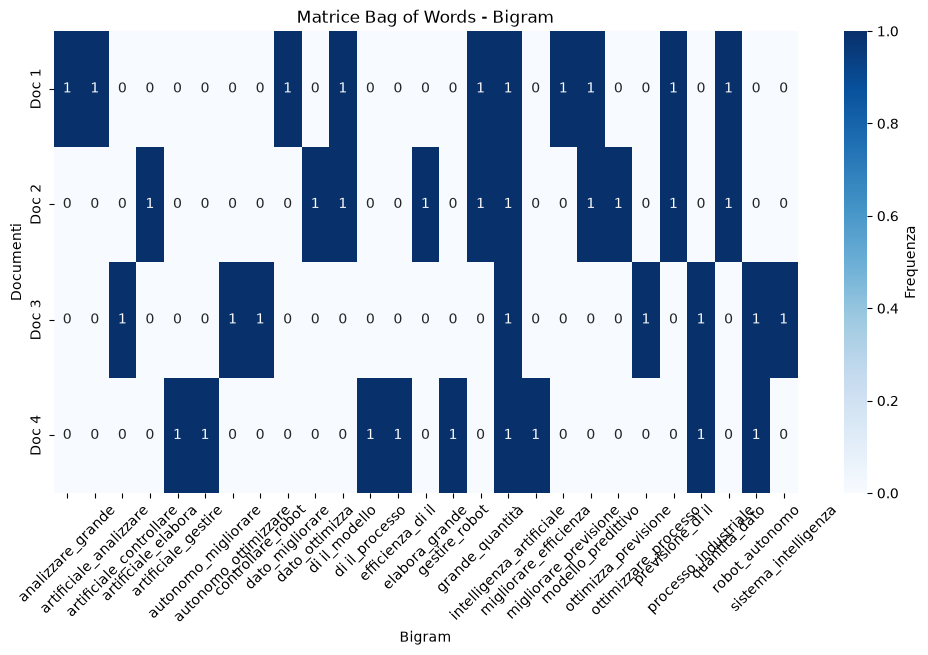

📊 Matrice di similarità tra documenti:


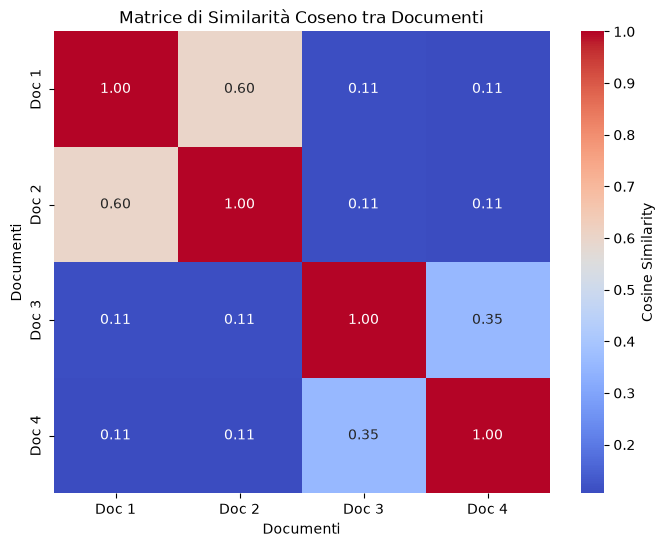

In [12]:
# Implementiamo Bag of Words usando i bigram
class BagOfWordsBigram:
    
    def __init__(self):
        # Il vocabolario conterrà i bigram e il loro indice
        self.vocabolario = {}
        self.vocabolario_inverso = {}
        self.dimensione_vocab = 0
    
    def genera_bigrams(self, parole):
        """Genera tutti i bigram consecutivi"""
        
        # Un bigram è formato da due token consecutivi
        return [f"{parole[i]}_{parole[i+1]}" 
                for i in range(len(parole)-1)]
    
    
    def costruisci_vocabolario(self, documenti):
        """Costruisce il vocabolario dei bigram presenti nei documenti"""
        
        tutti_bigram = set()
        
        for doc in documenti:
            
            # Pre-processing del documento
            pipeline = PipelinePreelaborazione()
            tokens = pipeline.processa_testo(doc)
            
            # Generiamo i bigram del documento
            bigram_doc = self.genera_bigrams(tokens)
            
            # Aggiungiamo i bigram al vocabolario
            tutti_bigram.update(bigram_doc)
        
        # Assegniamo un indice a ogni bigram
        for i, bigram in enumerate(sorted(tutti_bigram)):
            self.vocabolario[bigram] = i
            self.vocabolario_inverso[i] = bigram
        
        self.dimensione_vocab = len(self.vocabolario)
        
        print(f"📚 Vocabolario costruito: {self.dimensione_vocab} bigram unici")
        
        for i, bigram in enumerate(sorted(self.vocabolario.keys()), 1):
            print(f"{i}. {bigram}")
    
    
    def documento_to_vettore(self, documento):
        """Converte un documento in un vettore BoW di bigram"""
        
        # Pre-processing del documento
        pipeline = PipelinePreelaborazione()
        tokens = pipeline.processa_testo(documento)
        
        # Generiamo i bigram del documento
        bigram_doc = self.genera_bigrams(tokens)
        
        # Creiamo il vettore: una posizione per ogni bigram del vocabolario
        vettore = np.zeros(self.dimensione_vocab)
        
        # Contiamo quante volte compare ogni bigram
        for bigram in bigram_doc:
            if bigram in self.vocabolario:
                indice = self.vocabolario[bigram]
                vettore[indice] += 1
        
        return vettore
    
    
    def trasforma_documenti(self, documenti):
        """Trasforma tutti i documenti in una matrice BoW"""
        
        matrice = []
        
        for doc in documenti:
            vettore = self.documento_to_vettore(doc)
            matrice.append(vettore)
        
        return np.array(matrice)


# ============================================================
# TEST CON DOCUMENTI DI ESEMPIO
# ============================================================

documenti_esempio = [
    "L'intelligenza artificiale analizza grandi quantità di dati per migliorare le previsioni dei modelli predittivi.",
    "L'intelligenza artificiale elabora grandi quantità di dati e ottimizza le previsioni dei modelli predittivi.",
    "I sistemi di intelligenza artificiale controllano robot autonomi per ottimizzare i processi industriali.",
    "L'intelligenza artificiale gestisce robot autonomi e migliora l'efficienza dei processi industriali."
]


# Creiamo il modello BoW basato sui bigram
bow_bigram = BagOfWordsBigram()

# Costruiamo il vocabolario
bow_bigram.costruisci_vocabolario(documenti_esempio)

# Trasformiamo i documenti in vettori numerici
matrice_bow = bow_bigram.trasforma_documenti(documenti_esempio)


# ============================================================
# VISUALIZZIAMO LA MATRICE BoW
# ============================================================

df_bow = pd.DataFrame(
    matrice_bow,
    columns=list(bow_bigram.vocabolario.keys()),
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

#print(df_bow)


# Heatmap della matrice BoW
plt.figure(figsize=(12, 6))

sns.heatmap(
    df_bow,
    annot=True,
    cmap='Blues',
    cbar_kws={'label': 'Frequenza'}
)

plt.title('Matrice Bag of Words - Bigram')
plt.xlabel('Bigram')
plt.ylabel('Documenti')
plt.xticks(rotation=45)

plt.show()


# ============================================================
# SIMILARITÀ TRA I DOCUMENTI
# ============================================================

# Confrontiamo i vettori dei documenti usando la similarità coseno
similarita = cosine_similarity(matrice_bow)

# Creiamo un DataFrame per visualizzare i risultati
df_similarita = pd.DataFrame(
    similarita,
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))],
    columns=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

print("📊 Matrice di similarità tra documenti:")
#print(df_similarita)


# Visualizziamo la similarità con una heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_similarita,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    cbar_kws={'label': 'Cosine Similarity'}
)

plt.title('Matrice di Similarità Coseno tra Documenti')
plt.xlabel('Documenti')
plt.ylabel('Documenti')

plt.show()

## Confronto utilizzo token singoli VS Bigrams in BoW


📚 Vocabolario (ngram=1): 29 elementi

📚 Vocabolario (ngram=2): 37 elementi


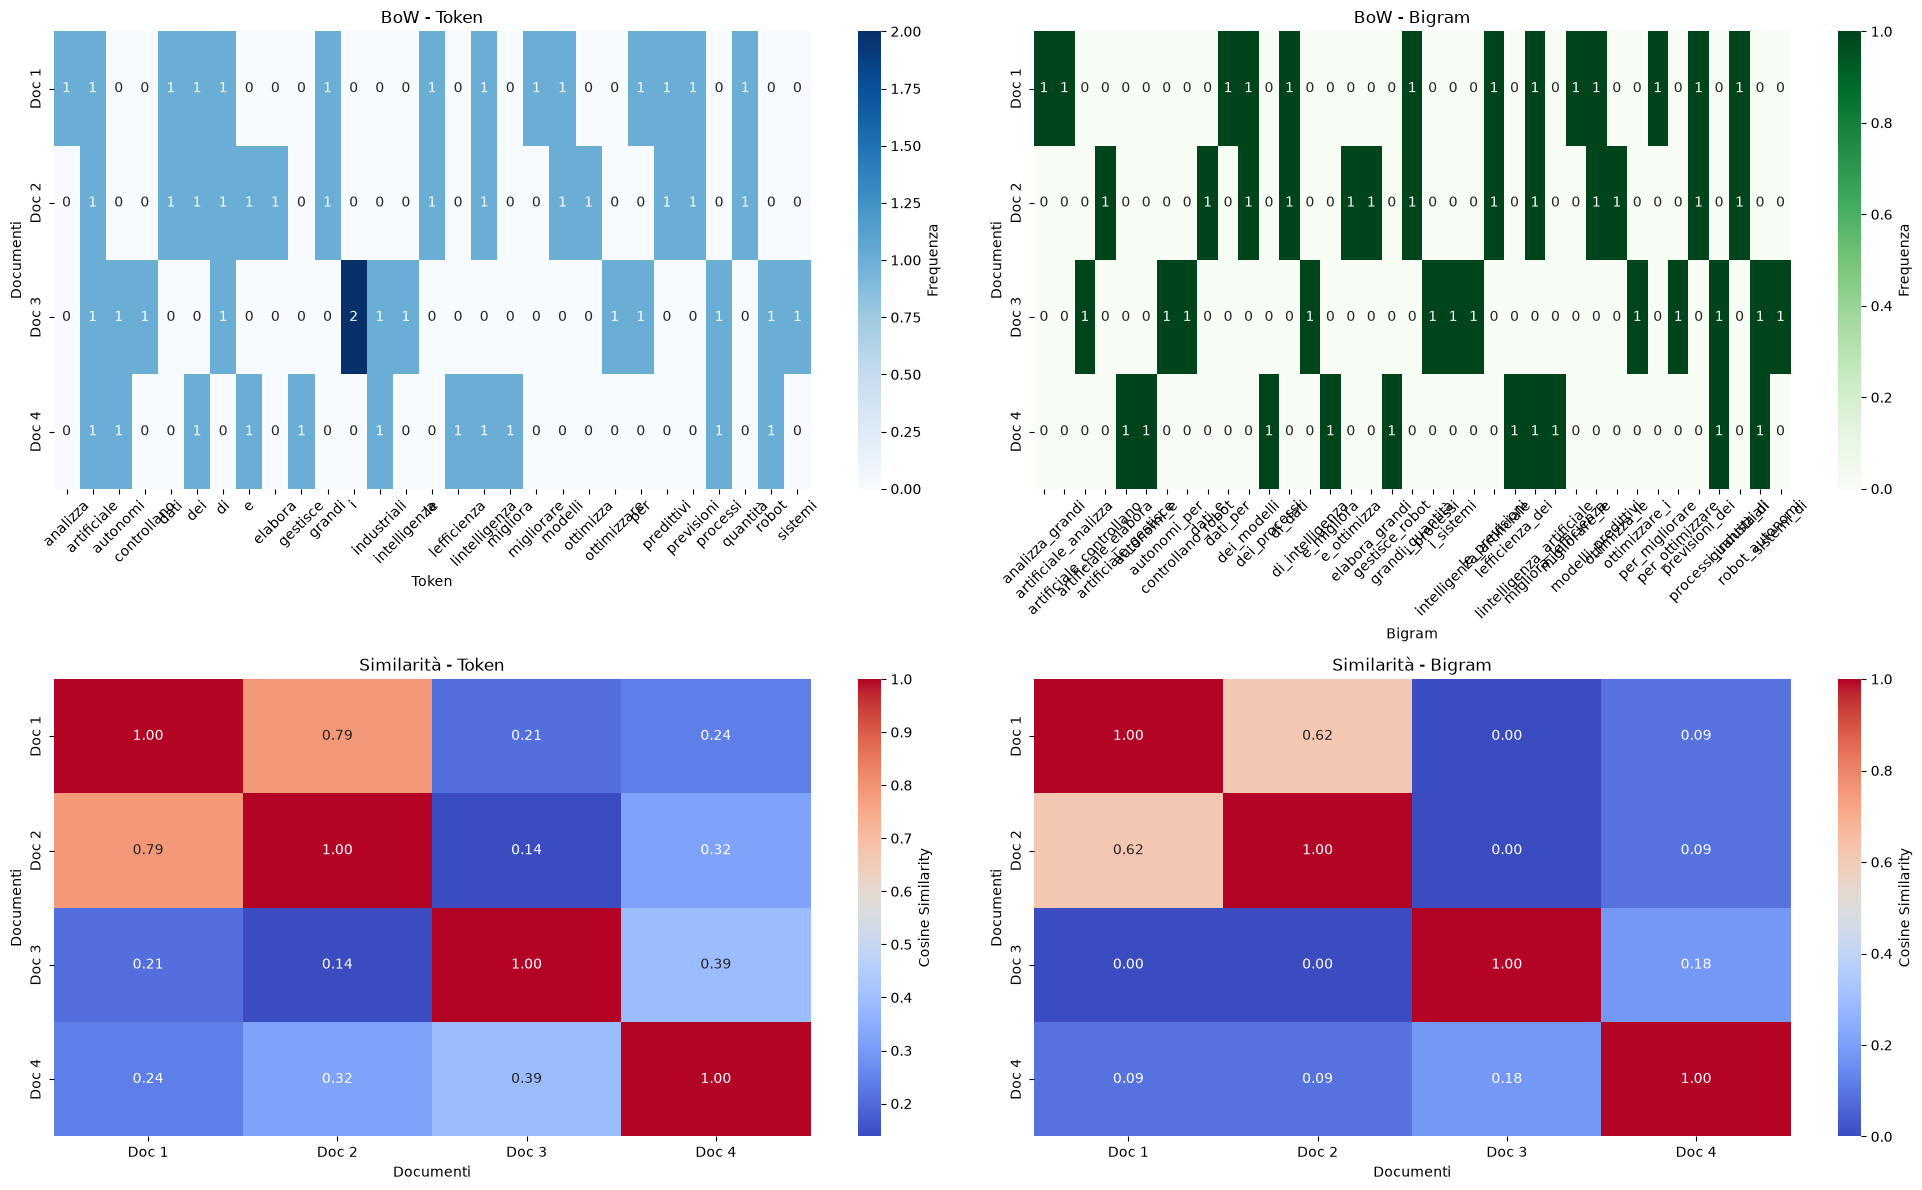

In [13]:
# ============================================================
# BAG OF WORDS: CONFRONTO TRA TOKEN E BIGRAM
# ============================================================

class BagOfWords:
    def __init__(self):
        # Il vocabolario associa ogni feature a un indice numerico
        self.vocabolario = {}
        self.vocabolario_inverso = {}
        self.dimensione_vocab = 0

    def costruisci_vocabolario(self, documenti, ngram=1):
        """Costruisce il vocabolario usando token o bigram"""
        
        tutti_ngrams = set()

        for doc in documenti:
            parole = self._preprocess(doc)

            # ngram=1 → parole singole
            # ngram=2 → coppie di parole consecutive
            if ngram == 1:
                tokens = parole
            elif ngram == 2:
                tokens = self._genera_bigrams(parole)
            else:
                raise ValueError("ngram supportati: 1 (token) o 2 (bigram)")

            # Raccogliamo tutte le feature presenti nei documenti
            tutti_ngrams.update(tokens)

        # Ogni feature riceve un indice nel vocabolario
        for i, token in enumerate(sorted(tutti_ngrams)):
            self.vocabolario[token] = i
            self.vocabolario_inverso[i] = token

        self.dimensione_vocab = len(self.vocabolario)

        print(f"\n📚 Vocabolario (ngram={ngram}): {self.dimensione_vocab} elementi")


    def documento_to_vettore(self, documento, ngram=1):
        """Converte un documento in un vettore BoW"""
        
        parole = self._preprocess(documento)

        # Decidiamo quali feature utilizzare
        if ngram == 1:
            tokens = parole
        elif ngram == 2:
            tokens = self._genera_bigrams(parole)
        else:
            raise ValueError("ngram supportati: 1 o 2")

        # Ogni posizione del vettore corrisponde a una feature
        vettore = np.zeros(self.dimensione_vocab)

        # Contiamo quante volte compare ogni feature nel documento
        for token in tokens:
            if token in self.vocabolario:
                indice = self.vocabolario[token]
                vettore[indice] += 1

        return vettore


    def trasforma_documenti(self, documenti, ngram=1):
        """Trasforma i documenti in una matrice BoW"""
        
        matrice = []

        for doc in documenti:
            vettore = self.documento_to_vettore(doc, ngram=ngram)
            matrice.append(vettore)

        # Ogni riga rappresenta un documento
        # Ogni colonna rappresenta una feature
        return np.array(matrice)


    # ========================================================
    # FUNZIONI DI SUPPORTO
    # ========================================================

    def _preprocess(self, doc):
        # Semplice pre-processing: minuscolo e rimozione punteggiatura
        import re
        
        doc = doc.lower()
        doc = re.sub(r'[^\w\s]', '', doc)
        
        return doc.split()


    def _genera_bigrams(self, parole):
        # Un bigram è formato da due parole consecutive
        return [
            f"{parole[i]}_{parole[i+1]}"
            for i in range(len(parole)-1)
        ]


# ============================================================
# DOCUMENTI DI ESEMPIO
# ============================================================

documenti_esempio = [
    "L'intelligenza artificiale analizza grandi quantità di dati per migliorare le previsioni dei modelli predittivi.",
    "L'intelligenza artificiale elabora grandi quantità di dati e ottimizza le previsioni dei modelli predittivi.",
    "I sistemi di intelligenza artificiale controllano robot autonomi per ottimizzare i processi industriali.",
    "L'intelligenza artificiale gestisce robot autonomi e migliora l'efficienza dei processi industriali."
]


# ============================================================
# BAG OF WORDS CON TOKEN
# ============================================================

bow_token = BagOfWords()

# Con ngram=1 le feature sono le singole parole
bow_token.costruisci_vocabolario(
    documenti_esempio,
    ngram=1
)

matrice_token = bow_token.trasforma_documenti(
    documenti_esempio,
    ngram=1
)

# Confrontiamo i documenti attraverso i loro vettori
similarita_token = cosine_similarity(matrice_token)


# ============================================================
# BAG OF WORDS CON BIGRAM
# ============================================================

bow_bigram = BagOfWords()

# Con ngram=2 le feature sono coppie di parole consecutive
bow_bigram.costruisci_vocabolario(
    documenti_esempio,
    ngram=2
)

matrice_bigram = bow_bigram.trasforma_documenti(
    documenti_esempio,
    ngram=2
)

# Confrontiamo i documenti usando i vettori di bigram
similarita_bigram = cosine_similarity(matrice_bigram)


# ============================================================
# VISUALIZZAZIONE DELLE MATRICI BoW
# ============================================================

df_token = pd.DataFrame(
    matrice_token,
    columns=list(bow_token.vocabolario.keys()),
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

df_bigram = pd.DataFrame(
    matrice_bigram,
    columns=list(bow_bigram.vocabolario.keys()),
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)


# Creiamo quattro grafici per confrontare token e bigram
fig, axes = plt.subplots(2, 2, figsize=(20, 12))


# BoW con token
sns.heatmap(
    df_token,
    annot=True,
    cmap='Blues',
    ax=axes[0,0],
    cbar_kws={'label': 'Frequenza'}
)

axes[0,0].set_title('BoW - Token')
axes[0,0].set_xlabel('Token')
axes[0,0].set_ylabel('Documenti')
axes[0,0].tick_params(axis='x', rotation=45)


# BoW con bigram
sns.heatmap(
    df_bigram,
    annot=True,
    cmap='Greens',
    ax=axes[0,1],
    cbar_kws={'label': 'Frequenza'}
)

axes[0,1].set_title('BoW - Bigram')
axes[0,1].set_xlabel('Bigram')
axes[0,1].set_ylabel('Documenti')
axes[0,1].tick_params(axis='x', rotation=45)


# ============================================================
# VISUALIZZAZIONE DELLA SIMILARITÀ
# ============================================================

df_sim_token = pd.DataFrame(
    similarita_token,
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))],
    columns=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)

df_sim_bigram = pd.DataFrame(
    similarita_bigram,
    index=[f"Doc {i+1}" for i in range(len(documenti_esempio))],
    columns=[f"Doc {i+1}" for i in range(len(documenti_esempio))]
)


# Similarità calcolata sui token
sns.heatmap(
    df_sim_token,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    ax=axes[1,0],
    cbar_kws={'label': 'Cosine Similarity'}
)

axes[1,0].set_title('Similarità - Token')
axes[1,0].set_xlabel('Documenti')
axes[1,0].set_ylabel('Documenti')


# Similarità calcolata sui bigram
sns.heatmap(
    df_sim_bigram,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    ax=axes[1,1],
    cbar_kws={'label': 'Cosine Similarity'}
)

axes[1,1].set_title('Similarità - Bigram')
axes[1,1].set_xlabel('Documenti')
axes[1,1].set_ylabel('Documenti')


plt.tight_layout()
plt.show()